In [3]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

%matplotlib inline

data = xr.open_dataset(r"D:\python class\ESE5023\200301_202006-C3S-L3_GHG-PRODUCTS-OBS4MIPS-MERGED-v4.3.nc")
ch4 = data["xch4"].sel(time=slice("2003-01", "2020-06"))
# 去除缺测值，再转换为 ppb
ch4 = ch4.where(~np.isclose(ch4, 1e20)).astype(float) * 1e9
ch4

<xarray.DataArray 'xch4' (time: 210, lat: 36, lon: 72)> Size: 4MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
...
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]],

       [[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(210, 36, 72))
Coordinates:
  * time     (time) datetime64[ns] 2kB 2003-01-16T12:00:00 ... 2020-06-16
  * lat      (lat) float64 288B -87.5 -82.5 -77.5 -72.5 ... 72.5 77.5 82.5 87.5
  * lon      (lon) float64 576B -177.5 -172.5 -167.5 ... 167.5 172.5 177.5
Attributes:
    standard_name:  dry_atmosphere_mole_fraction_of_methane
    long_name:      column-average dry-air mole fraction of atmospheric methane
    units:          1
    cell_methods:   time: mean
    fill_value:     1e+20
    comment:        Satellite retrieved column-average dry-air mole fraction ...

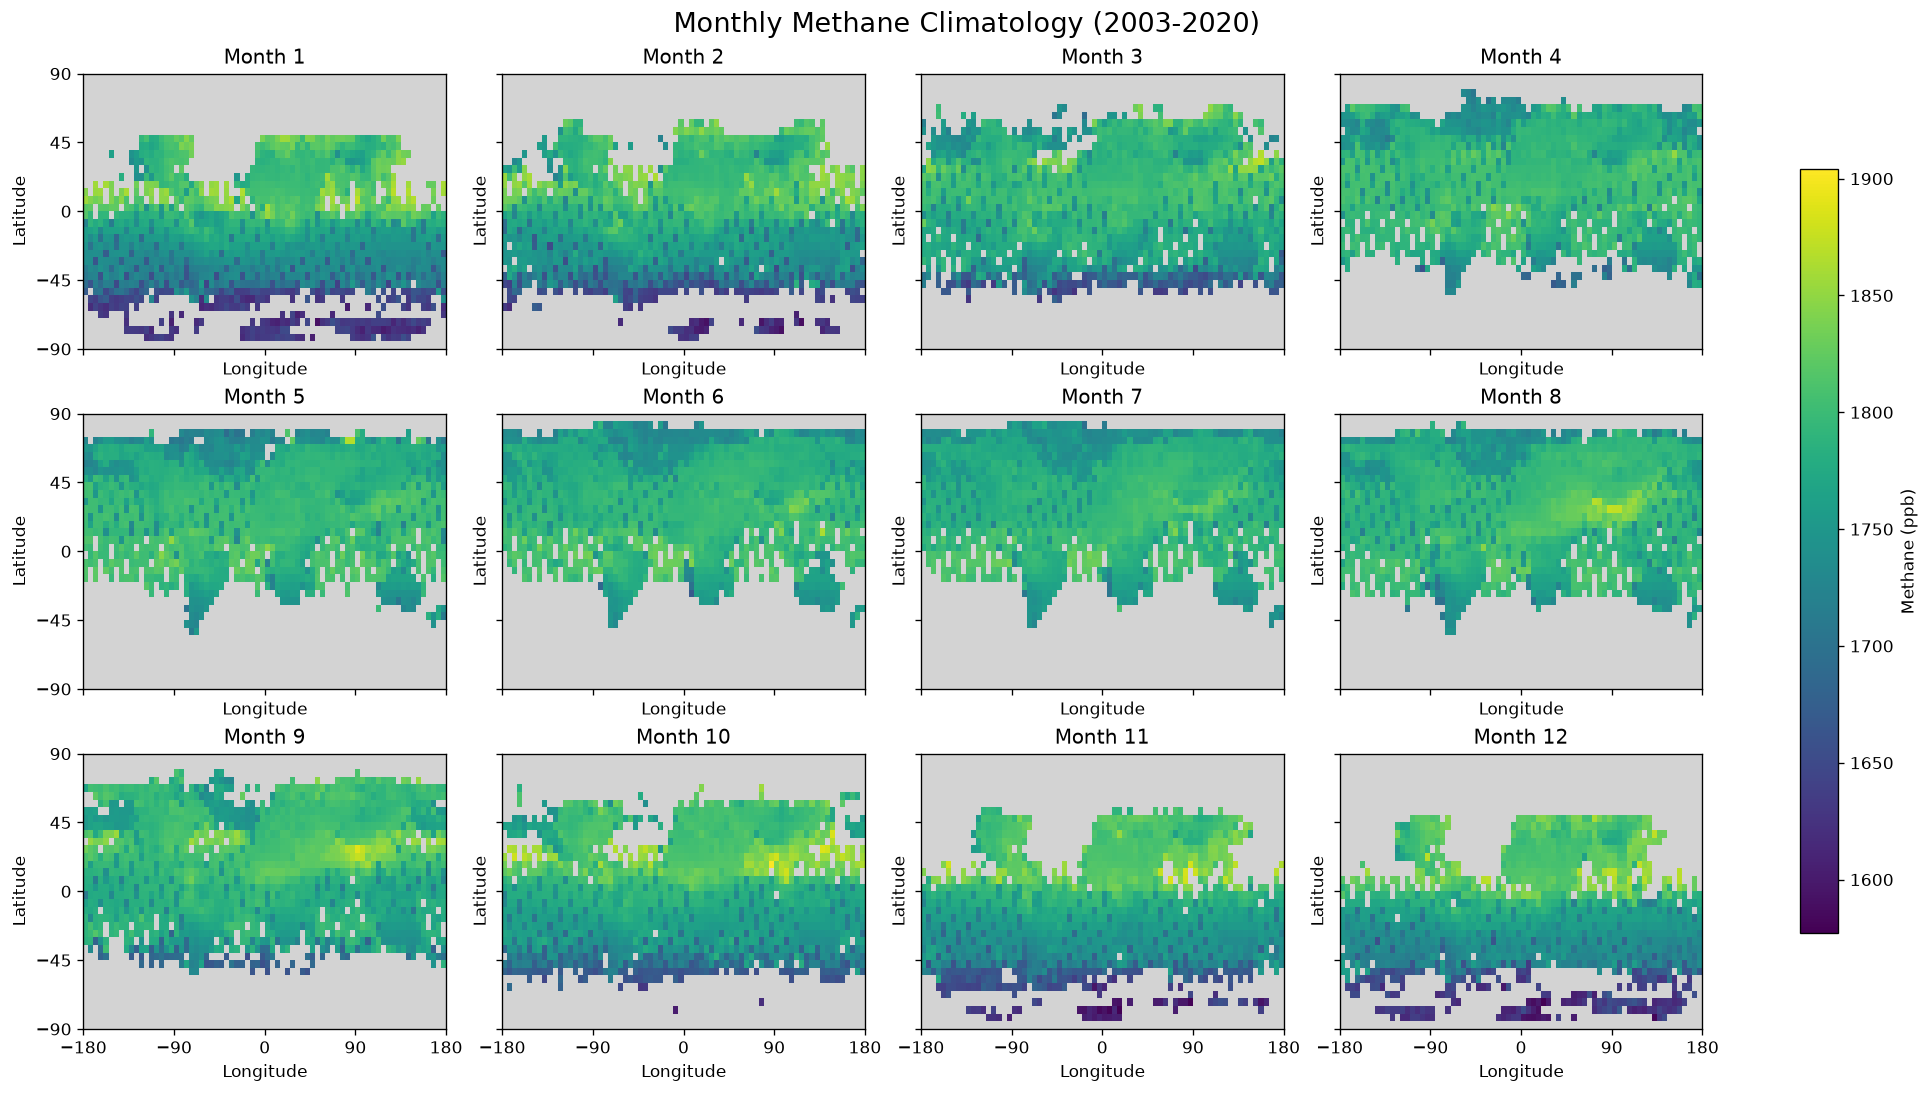

In [2]:
# 1.1
climatology = ch4.groupby("time.month").mean(dim="time", skipna=True)
#用全部月份的最小值和最大值统一色标，便于比较不同月份
vmin = float(climatology.min())
vmax = float(climatology.max())

fig, axes = plt.subplots(3, 4, figsize=(16, 9), sharex=True, sharey=True,dpi=120, constrained_layout=True)
#i从0开始，月份从1开始
for i, ax in enumerate(axes.ravel()):
    im = ax.pcolormesh(
        data["lon"],
        data["lat"],
        climatology.sel(month=i + 1),
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        shading="auto")
    ax.set_title(f"Month {i + 1}")
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_xticks([-180, -90, 0, 90, 180])
    ax.set_yticks([-90, -45, 0, 45, 90])
    ax.set_facecolor("lightgray")
    
fig.colorbar(im, ax=axes.ravel().tolist(),label="Methane (ppb)", shrink=0.8)
fig.suptitle("Monthly Methane Climatology (2003-2020)", fontsize=16)
plt.show()


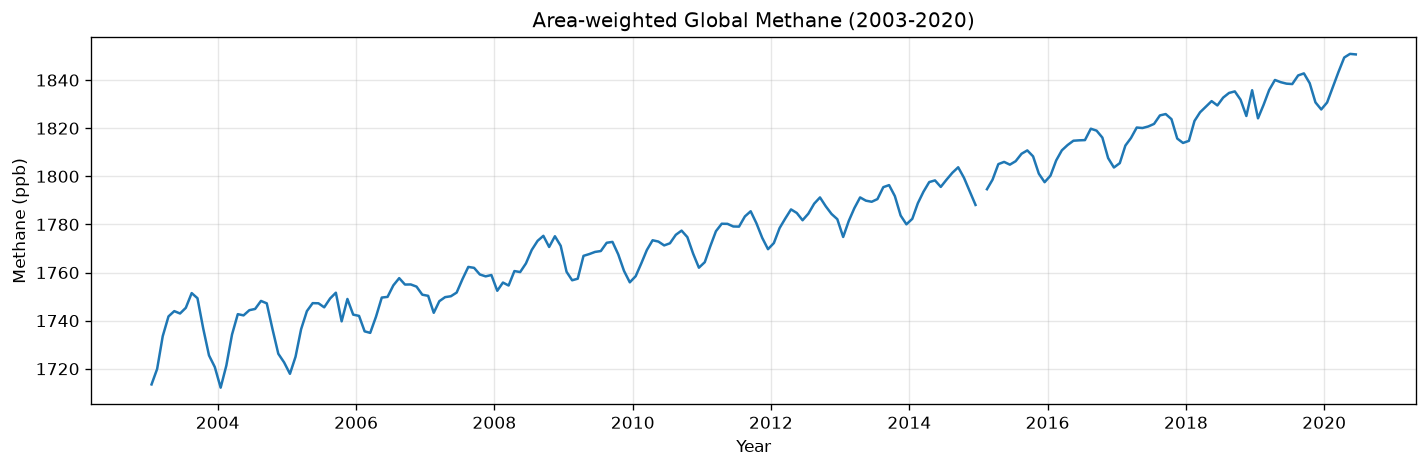

In [3]:
# 1.2
# 不同纬度的网格面积不同，使用纬度余弦加权
weights = np.cos(np.deg2rad(ch4["lat"]))

global_mean = ch4.weighted(weights).mean(dim=["lat", "lon"], skipna=True)

plt.figure(figsize=(12, 4), dpi=120)

plt.plot(global_mean["time"], global_mean, color="tab:blue")

plt.xlabel("Year")
plt.ylabel("Methane (ppb)")
plt.title("Area-weighted Global Methane (2003-2020)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

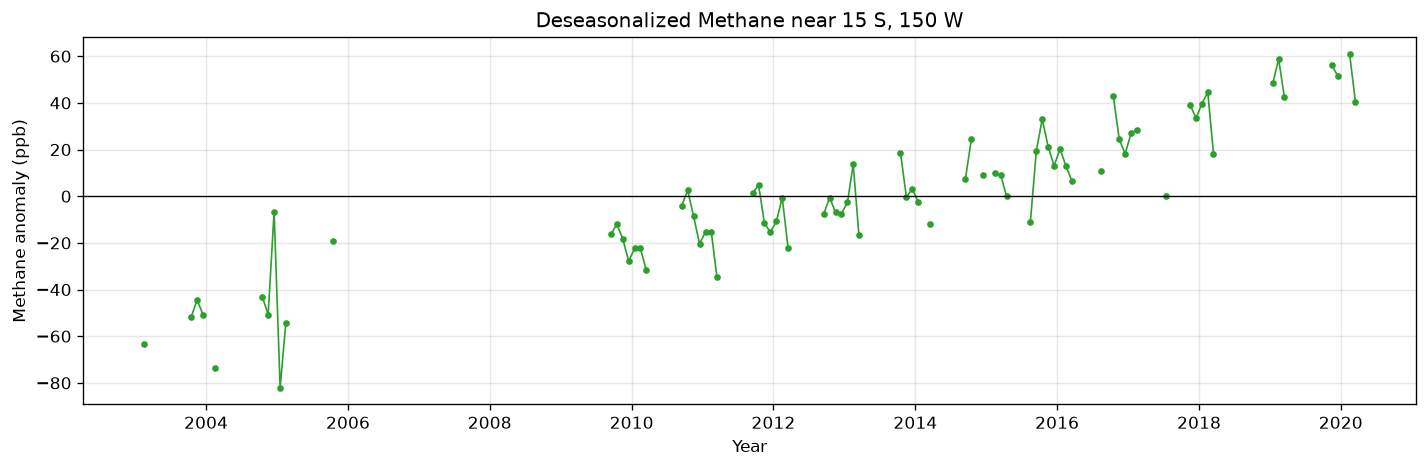

Selected latitude: -12.5
Selected longitude: -147.5
Valid months: 77 / 210


In [4]:
#1.3
#选取距离 15°S、150°W 最近的网格
point = ch4.sel(lat=-15, lon=-150, method="nearest")

#计算该网格的逐月气候态
point_climatology = point.groupby("time.month").mean(dim="time", skipna=True)

#原始值减去对应月份的气候态
deseasonalized = point.groupby("time.month") - point_climatology

plt.figure(figsize=(12, 4), dpi=120)

plt.plot(
    deseasonalized["time"],
    deseasonalized,
    "-o",
    color="tab:green",
    markersize=3,
    linewidth=1)

plt.axhline(0, color="black", linewidth=0.8)

plt.xlabel("Year")
plt.ylabel("Methane anomaly (ppb)")
plt.title("Deseasonalized Methane near 15 S, 150 W")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("Selected latitude:", float(point["lat"]))
print("Selected longitude:", float(point["lon"]))
print("Valid months:", int(point.count()), "/", point.size)

In [5]:
#2
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt

%matplotlib inline

data = xr.open_dataset(r"D:\python class\ESE5023\NOAA_NCDC_ERSST_v3b_SST.nc")

data

<xarray.Dataset> Size: 44MB
Dimensions:  (time: 684, lat: 89, lon: 180)
Coordinates:
  * time     (time) datetime64[ns] 5kB 1960-01-15 1960-02-15 ... 2016-12-15
  * lat      (lat) float32 356B -88.0 -86.0 -84.0 -82.0 ... 82.0 84.0 86.0 88.0
  * lon      (lon) float32 720B 0.0 2.0 4.0 6.0 8.0 ... 352.0 354.0 356.0 358.0
Data variables:
    sst      (time, lat, lon) float32 44MB ...
Attributes:
    Conventions:  IRIDL
    source:       https://iridl.ldeo.columbia.edu/SOURCES/.NOAA/.NCDC/.ERSST/...
    history:      extracted and cleaned by Ryan Abernathey for Research Compu...

In [6]:
#2.1
#选取Niño3.4区域
sst = data["sst"].sel(lat=slice(-5, 5),lon=slice(190, 240))

#使用纬度余弦加权，计算区域平均 SST
weights = np.cos(np.deg2rad(sst["lat"]))

sst_mean = sst.weighted(weights).mean(dim=["lat", "lon"],skipna=True)

#计算1-12月平均
climatology = sst_mean.groupby("time.month").mean(dim="time")

#每个月减去对应月份的气候态
anomaly = sst_mean.groupby("time.month") - climatology

print("Monthly SST climatology (°C):")
print(climatology.to_series().round(2))

Monthly SST climatology (°C):
month
1     26.570000
2     26.740000
3     27.240000
4     27.690001
5     27.799999
6     27.600000
7     27.200001
8     26.820000
9     26.740000
10    26.719999
11    26.690001
12    26.610001
Name: sst, dtype: float32


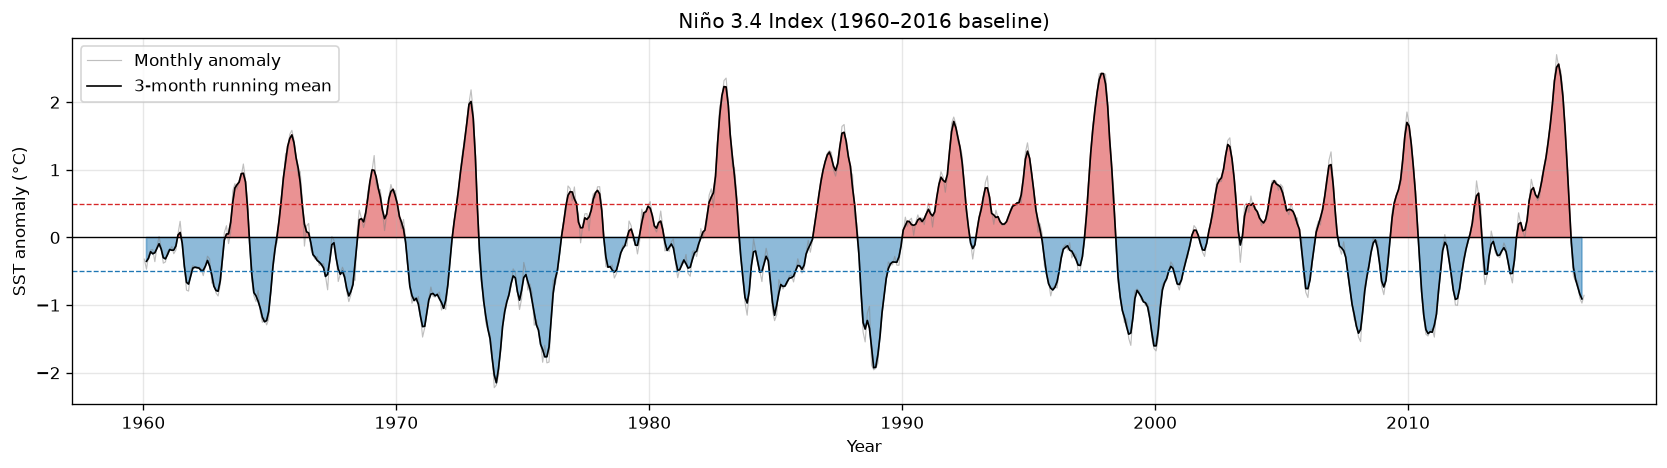

In [7]:
#2.2
nino34 = anomaly.rolling(time=3, center=True, min_periods=3).mean()
time = nino34["time"].values
index = nino34.values

fig, ax = plt.subplots(figsize=(14, 4), dpi=120)
#灰线是原始月异常，黑线是3个月滑动平均，红色填充正异常，蓝色填充负异常
ax.plot(time, anomaly.values, color="gray", alpha=0.5,linewidth=0.7, label="Monthly anomaly")
ax.plot(time, index, color="black", linewidth=1,label="3-month running mean")

ax.fill_between(time, 0, index, where=index >= 0,color="tab:red", alpha=0.5, interpolate=True)
ax.fill_between(time, 0, index, where=index < 0,color="tab:blue", alpha=0.5, interpolate=True)

ax.axhline(0, color="black", linewidth=0.8)
ax.axhline(0.5, color="tab:red", linestyle="--", linewidth=0.8)
ax.axhline(-0.5, color="tab:blue", linestyle="--", linewidth=0.8)

ax.set_xlabel("Year")
ax.set_ylabel("SST anomaly (°C)")
ax.set_title("Niño 3.4 Index (1960–2016 baseline)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [7]:
#3
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
from pathlib import Path

%matplotlib inline
data = xr.open_dataset("POWER_T2M_2001_2020.nc", engine="netcdf4")
data

<xarray.Dataset> Size: 231kB
Dimensions:  (time: 260, lat: 11, lon: 10)
Coordinates:
  * time     (time) int64 2kB 200101 200102 200103 ... 202011 202012 202013
  * lat      (lat) float64 88B 20.0 20.5 21.0 21.5 22.0 ... 23.5 24.0 24.5 25.0
  * lon      (lon) float64 80B 111.2 111.9 112.5 113.1 ... 115.6 116.2 116.9
Data variables:
    T2M      (time, lat, lon) float64 229kB ...
Attributes: (12/22)
    acknowledgement:           The Prediction Of Worldwide Energy Resources (...
    comment:                   POWER data version 10.0.0 uses the source data...
    conventions:               CF-1.8, ACDD-1.3
    creator_email:             bradley.macpherson@nasa.gov
    creator_name:              Bradley Macpherson
    derived_from:              The data products are derived from data partne...
    ...                        ...
    publisher_name:            Paul Stackhouse
    references:                https://power.larc.nasa.gov
    source:                    Prediction Of Worldwide Energy Resource (POWER)
    standard_name_vocabulary:  CF Standard Name Table v72
    summary:                   The POWER project provides solar and meteorolo...
    version:                   POWER Version 10.0.0

In [8]:
#取时间的最后两位。只保留 1–12 月
month = data["time"] % 100
temperature = data["T2M"].where(month <= 12, drop=True)
#将整数时间转换为日期
dates = pd.to_datetime(temperature["time"].values.astype(str), format="%Y%m")
temperature = temperature.assign_coords(time=dates)

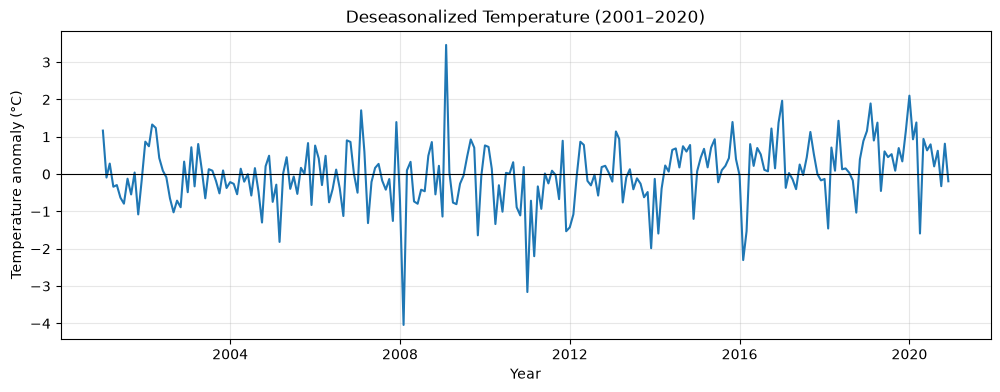

In [9]:
#3.1区域平均气温减去对应月份的多年平均，折线图
weights = np.cos(np.deg2rad(temperature["lat"]))
regional_mean = temperature.weighted(weights).mean(dim=["lat", "lon"])

climatology = regional_mean.groupby("time.month").mean(dim="time")
anomaly = regional_mean.groupby("time.month") - climatology

plt.figure(figsize=(12, 4))
plt.plot(anomaly["time"], anomaly)
plt.axhline(0, color="black", linewidth=0.8)
plt.xlabel("Year")
plt.ylabel("Temperature anomaly (°C)")
plt.title("Deseasonalized Temperature (2001–2020)")
plt.grid(alpha=0.3)
plt.show()

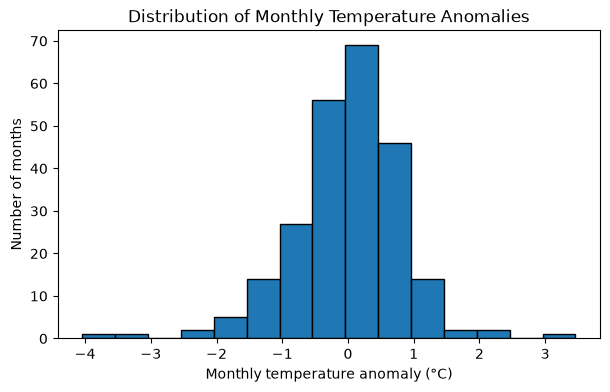

In [5]:
#3.2直方图表示月异常通常落在哪个范围
plt.figure(figsize=(7, 4))
plt.hist(anomaly.values, bins=15, edgecolor="black")
plt.xlabel("Monthly temperature anomaly (°C)")
plt.ylabel("Number of months")
plt.title("Distribution of Monthly Temperature Anomalies")
plt.show()

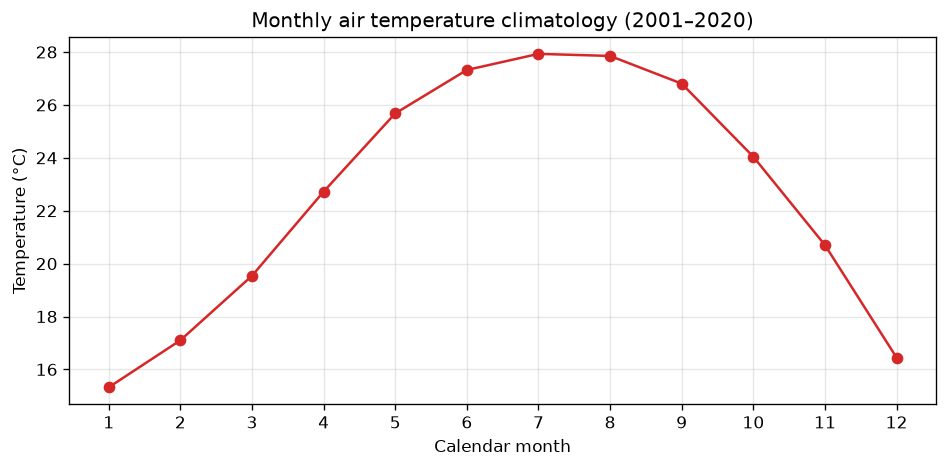

In [11]:
#3.3折线
fig, ax = plt.subplots(figsize=(8, 4), dpi=120)
ax.plot(climatology["month"], climatology, "o-", color="tab:red")
ax.set(title="Monthly air temperature climatology (2001–2020)",
       xlabel="Calendar month", ylabel="Temperature (°C)")
ax.set_xticks(np.arange(1, 13))
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

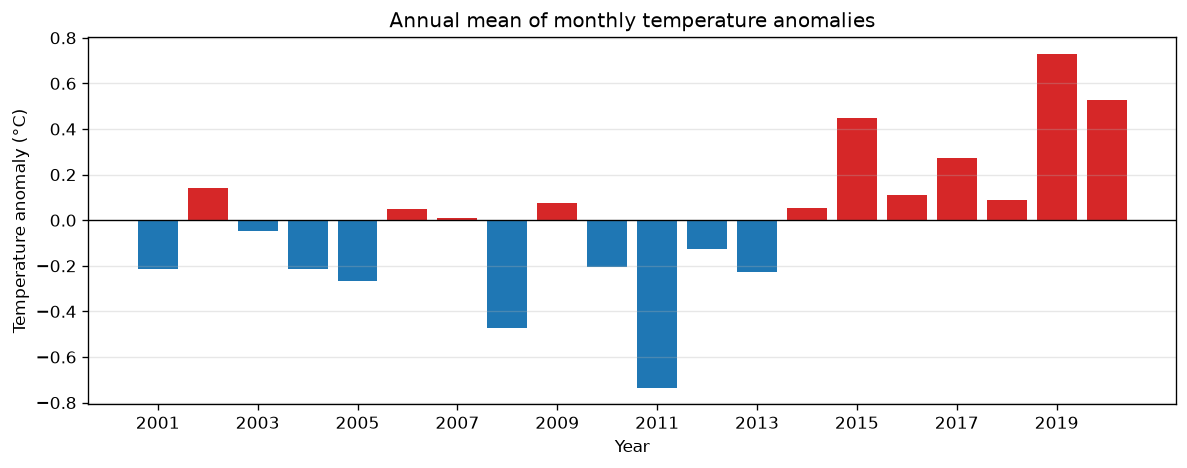

In [13]:
#3.4按年平均的月异常，每个月等权
annual_anomaly = anomaly.groupby("time.year").mean(dim="time")
colors = np.where(annual_anomaly.values >= 0, "tab:red", "tab:blue")

fig, ax = plt.subplots(figsize=(10, 4), dpi=120)
ax.bar(annual_anomaly["year"], annual_anomaly, color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set(title="Annual mean of monthly temperature anomalies",xlabel="Year", ylabel="Temperature anomaly (°C)")
ax.set_xticks(np.arange(2001, 2021, 2))
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()

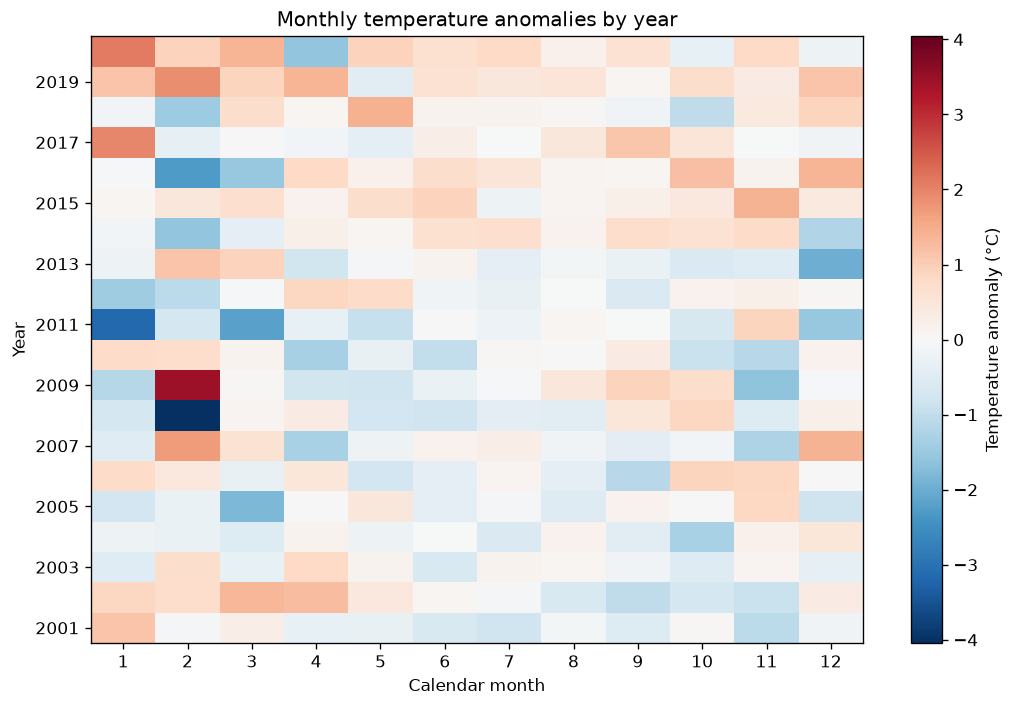

In [14]:
#3.5年-月异常热图
heatmap = pd.DataFrame({"year": anomaly["time"].dt.year.values,
                        "month": anomaly["time"].dt.month.values,
                        "anomaly": anomaly.values}).pivot(index="year", columns="month", values="anomaly")
limit = np.abs(heatmap.values).max()

fig, ax = plt.subplots(figsize=(9, 6), dpi=120)
im = ax.pcolormesh(heatmap.columns, heatmap.index, 
                   heatmap.values,cmap="RdBu_r", vmin=-limit, vmax=limit, shading="nearest")
ax.set(title="Monthly temperature anomalies by year",xlabel="Calendar month", ylabel="Year")
ax.set_xticks(np.arange(1, 13))
ax.set_yticks(np.arange(2001, 2021, 2))

fig.colorbar(im, ax=ax, label="Temperature anomaly (°C)")
fig.tight_layout()
plt.show()

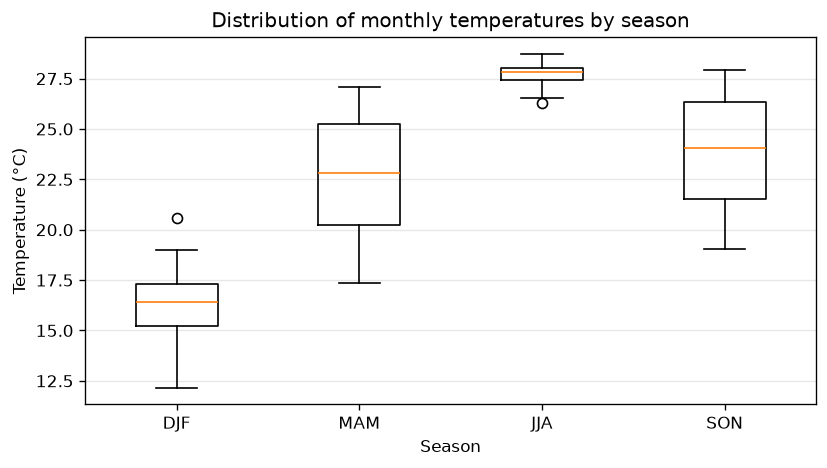

In [15]:
#3.6比较四季中区域月平均气温的分布，箱线图
seasons = ["DJF", "MAM", "JJA", "SON"]
season_values = [regional_mean.where(regional_mean["time"].dt.season == season, drop=True).values
    for season in seasons]

fig, ax = plt.subplots(figsize=(7, 4), dpi=120)
ax.boxplot(season_values)
ax.set_xticks(np.arange(1, 5), seasons)
ax.set(title="Distribution of monthly temperatures by season",xlabel="Season", ylabel="Temperature (°C)")
ax.grid(axis="y", alpha=0.3)

fig.tight_layout()
plt.show()

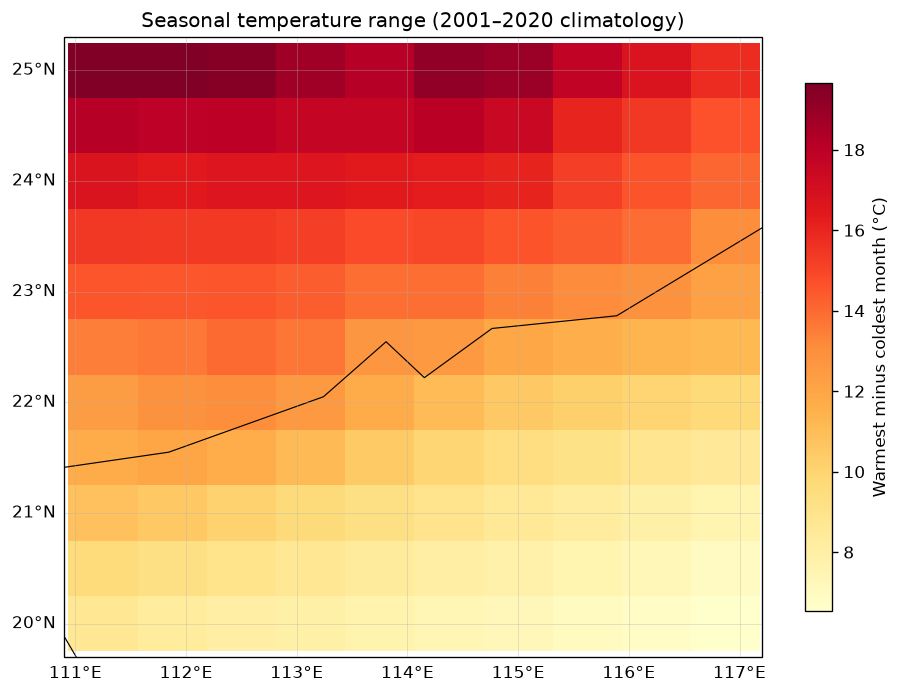

In [16]:
#3.7 最暖月气候态减去最冷月气候态，季节温差
grid_climatology = temperature.groupby("time.month").mean(dim="time")
seasonal_range = grid_climatology.max(dim="month") - grid_climatology.min(dim="month")

fig = plt.figure(figsize=(8, 6), dpi=120)
ax = plt.axes(projection=ccrs.PlateCarree())
im = ax.pcolormesh(seasonal_range["lon"], 
                   seasonal_range["lat"], 
                   seasonal_range,
                   cmap="YlOrRd", shading="auto", transform=ccrs.PlateCarree())
ax.set_extent([110.9, 117.2, 19.7, 25.3], crs=ccrs.PlateCarree())
ax.coastlines(resolution="110m", linewidth=0.7)
gl = ax.gridlines(draw_labels=True, linewidth=0.4, alpha=0.5)
gl.top_labels = False
gl.right_labels = False
ax.set_title("Seasonal temperature range (2001–2020 climatology)")
fig.colorbar(im, ax=ax, label="Warmest minus coldest month (°C)", shrink=0.8)
fig.tight_layout()
plt.show()